# Canwell weather stations and nearest HRRR-AK cells

Compare downloaded observations with hourly forecasts at the nearest native 3 km cell.
The tables show station metadata, usable observation dates, model overlap, and paired
data coverage. The plots show the full overlap and a configurable hourly window.

In [1]:
from pathlib import Path
import os
import re
import sys

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "data" / "canwell_readme.txt").is_file())
sys.path.insert(0, str(root / "scripts"))
from station_observations import read_look_eyrie

data = root / "data"
netcdf = Path(os.environ.get("CANWELL_NETCDF",
                            data / "hrrrak_canwell_f567_WY2020-WY2026.nc"))
look_dir = data / "look_eyrie"
canwell_dir = data / "canwell_weather_station_data"

# The Canwell logger export has no time zone. Change this if the logger setting is confirmed.
canwell_clock = "UTC"

# Optional UTC start dates for the two-week hourly zoom.
zoom_start = {"Look Eyrie AWS": None, "Canwell weather station": None}

## Observation sources and hourly alignment

**Look Eyrie AWS** uses the annual NRCS SNOTEL CSVs. The export headers label the
clock YST (fixed UTC−08:00). Temperature is instantaneous and wind is the
previous-hour vector-average speed. Hourly precipitation is the change in the
cumulative gauge reading over two consecutive hours from the same sensor.
Negative changes, gaps, and file or gauge transitions produce missing increments.
Where both gauges report, gauge 2 supplies the increment.

**Canwell weather station** uses the ten-minute Campbell Scientific logger export
shared by Miaja Coombs. Records 0–148 precede the first continuous clock segment
and include repeated timestamps around a clock change. Record 149 onward uses
provisional UTC. A check against HRRR-AK subdaily temperature variability supports
a near-UTC alignment, but the logger time zone still needs confirmation.
Wind is averaged and precipitation summed over six ten-minute records ending
at each UTC hour. Temperature and humidity use the on-hour record, with temperature
representing the final ten-minute average and humidity the on-hour sample.

The comparison uses observed variables with identifiable units and HRRR-AK
counterparts. The Canwell pressure column has no unit in the export, and the
shortwave record contains long stretches of unusually low readings. Both are
left out pending sensor and calibration checks.

In [2]:
def to_utc(times, clock):
    return pd.DatetimeIndex(times).tz_localize(clock).tz_convert("UTC")


def read_canwell(folder):
    path = folder / "WeatherStationData" / "CR1000_2_Table1.txt"
    columns = {"AirTC_Avg": "temp", "WS_ms_Avg": "wind",
               "RV_Pre_Accu_Tot": "precip_hourly", "RH": "rh"}
    raw = pd.read_csv(path, skiprows=[0, 2, 3], na_values=["NAN"],
                      usecols=["TIMESTAMP", "RECORD", *columns])
    raw = raw.loc[raw.RECORD.ge(149)].copy()
    raw.index = to_utc(pd.to_datetime(raw.TIMESTAMP), canwell_clock)
    assert raw.index.is_unique and raw.index.is_monotonic_increasing
    values = raw[list(columns)].rename(columns=columns).apply(pd.to_numeric, errors="coerce")
    values["precip_hourly"] *= 25.4  # interval total, inches to mm
    hourly = values.resample("h", closed="right", label="right")
    whole_hour = values.index == values.index.floor("h")
    output = values.loc[whole_hour, ["temp", "rh"]].reindex(hourly.size().index)
    output["wind"] = hourly.wind.mean().where(hourly.wind.count().eq(6))
    output["precip_hourly"] = hourly.precip_hourly.sum(min_count=6).where(hourly.size().eq(6))
    return output


observations = {
    "Look Eyrie AWS": read_look_eyrie(look_dir)[["temp", "wind", "precip_hourly"]],
    "Canwell weather station": read_canwell(canwell_dir),
}

## Station metadata, nearest cells, and coverage

Look Eyrie coordinates and elevation use the supplied SMET station metadata
(1,588 m). Its header also quotes a separate NRCS listing of 5,040 ft (~1,536 m).
The Canwell coordinates come from the station download README and match the
South Moraine station in the project site inventory, which supplies the 982 m
elevation. Grid elevation is HRRR-AK surface geopotential height. Model
temperature is converted to °C without an elevation correction.

In [3]:
look_header = (look_dir / "SMET-HEADER_LookEyrieSta_v1.txt").read_text()
look_lat, look_lon, look_elev = [
    float(re.search(rf"^{key} = ([-.0-9]+)", look_header, re.MULTILINE)[1])
    for key in ("latitude", "longitude", "altitude")
]
canwell_readme = (canwell_dir / "readme.txt").read_text()
canwell_lat, canwell_lon = map(float, re.search(
    r"location:\s*([-.0-9]+),\s*([-.0-9]+)", canwell_readme).groups())
inventory = (data / "canwell_readme.txt").read_text()
canwell_elev = float(re.search(
    r"### Canwell South Moraine Station ###\s+Elev\.: (\d+)m", inventory)[1])

sites = pd.DataFrame([
    ("Look Eyrie AWS", "USDA NRCS SNOTEL 768", look_lat, look_lon, look_elev, "YST (UTC−08:00)"),
    ("Canwell weather station", "South Moraine / CR1000_2", canwell_lat, canwell_lon,
     canwell_elev, f"{canwell_clock} (provisional)"),
], columns=["Station", "Source / ID", "Latitude", "Longitude", "Station elevation (m)", "Source clock"]
).set_index("Station")

paired = {}
grid_rows = []
coverage_rows = []
with xr.open_dataset(netcdf, engine="netcdf4", decode_timedelta=False) as ds:
    lat, lon = np.deg2rad(ds.latitude.values), np.deg2rad(ds.longitude.values)
    for station, site in sites.iterrows():
        obs = observations[station].dropna(how="all")
        a, b = np.deg2rad([site.Latitude, site.Longitude])
        distance = 2 * 6371.229 * np.arcsin(np.sqrt(
            np.sin((lat - a) / 2)**2 + np.cos(a) * np.cos(lat) * np.sin((lon - b) / 2)**2
        ))
        y, x = np.unravel_index(distance.argmin(), distance.shape)
        cell = ds.isel(y=y, x=x)
        model = pd.DataFrame({var: cell[var].values for var in obs},
                             index=to_utc(ds.time.values, "UTC"))
        model["temp"] -= 273.15
        start, end = max(obs.index.min(), model.index.min()), min(obs.index.max(), model.index.max())
        hours = pd.date_range(start, end, freq="h", name="UTC")
        paired[station] = pd.concat(
            {"Station": obs.reindex(hours), "HRRR-AK": model.reindex(hours)}, axis=1
        )
        grid_rows.append({
            "Station": station, "Years": f"{obs.index.min().year}–{obs.index.max().year}",
            "First observation (UTC)": obs.index.min().strftime("%Y-%m-%d %H:%M"),
            "Last observation (UTC)": obs.index.max().strftime("%Y-%m-%d %H:%M"),
            "First overlap (UTC)": start.strftime("%Y-%m-%d %H:%M"),
            "Last overlap (UTC)": end.strftime("%Y-%m-%d %H:%M"),
            "Cell latitude": cell.latitude.item(), "Cell longitude": cell.longitude.item(),
            "Grid y, x": f"{y}, {x}", "Cell distance (km)": distance[y, x],
            "Grid elevation (m)": cell.orog.isel(time=0).item(),
        })
        for var in obs:
            series = paired[station].xs(var, axis=1, level=1)
            n = series.notna().all(axis=1).sum()
            coverage_rows.append((station, var, len(hours), n, 100 * n / len(hours)))

grid_info = pd.DataFrame(grid_rows).set_index("Station")
display(sites.join(grid_info[["Years", "First observation (UTC)", "Last observation (UTC)"]]))
display(grid_info[["First overlap (UTC)", "Last overlap (UTC)", "Grid y, x",
                   "Cell latitude", "Cell longitude", "Cell distance (km)", "Grid elevation (m)"]
                 ].round(4))
labels = {"temp": "Air temperature (°C)", "wind": "Wind speed (m/s)",
          "precip_hourly": "Precipitation (mm)", "rh": "Relative humidity (%)"}
coverage = pd.DataFrame(coverage_rows, columns=["Station", "Variable", "Overlap hours",
                                                 "Paired hours", "Paired (%)"])
coverage["Variable"] = coverage.Variable.map(labels)
display(coverage.set_index(["Station", "Variable"]).round(1))

,Source / ID,Latitude,Longitude,Station elevation (m),Source clock,Years,First observation (UTC),Last observation (UTC)
Station,,,,,,,,
Look Eyrie AWS,USDA NRCS SNOTEL 768,63.32000,-145.60000,1588.0,YST (UTC−08:00),2019–2026,2019-09-09 18:00,2026-09-08 19:00
Canwell weather station,South Moraine / CR1000_2,63.35652,-145.65991,982.0,UTC (provisional),2025–2026,2025-10-07 22:00,2026-11-09 22:00


,First overlap (UTC),Last overlap (UTC),"Grid y, x",Cell latitude,Cell longitude,Cell distance (km),Grid elevation (m)
Station,,,,,,,
Look Eyrie AWS,2019-09-09 18:00,2026-09-08 19:00,"8, 6",63.3322,-145.5939,1.3947,1205.1875
Canwell weather station,2025-10-07 22:00,2026-10-01 04:00,"9, 5",63.3541,-145.6652,0.3755,1042.3125


Overlap hours  Paired hours  \
Station                 Variable                                             
Look Eyrie AWS          Air temperature (°C)           61346         61218   
                        Wind speed (m/s)               61346         61234   
                        Precipitation (mm)             61346         61182   
Canwell weather station Air temperature (°C)            8599          8599   
                        Relative humidity (%)           8599          8599   
                        Wind speed (m/s)                8599          8598   
                        Precipitation (mm)              8599          8598   

                                               Paired (%)  
Station                 Variable                           
Look Eyrie AWS          Air temperature (°C)         99.8  
                        Wind speed (m/s)             99.8  
                        Precipitation (mm)           99.7  
Canwell weather station Air temperature (°C)        100.0  
                        Relative humidity (%)       100.0  
                        Wind speed (m/s)            100.0  
                        Precipitation (mm)          100.0

## Time series

Daily averages use the same paired hours for both series and require at least 18
paired hours. Daily precipitation sums require all 24 paired hourly intervals,
binned into the UTC day in which the precipitation fell. Gaps remain visible.
The hourly panels show the two-week zoom. Station wind summarizes the preceding
hour while HRRR-AK wind is the 10 m valid-time value. Gauge precipitation can
undercatch snowfall or reflect delayed melt, so interpret winter totals with care.

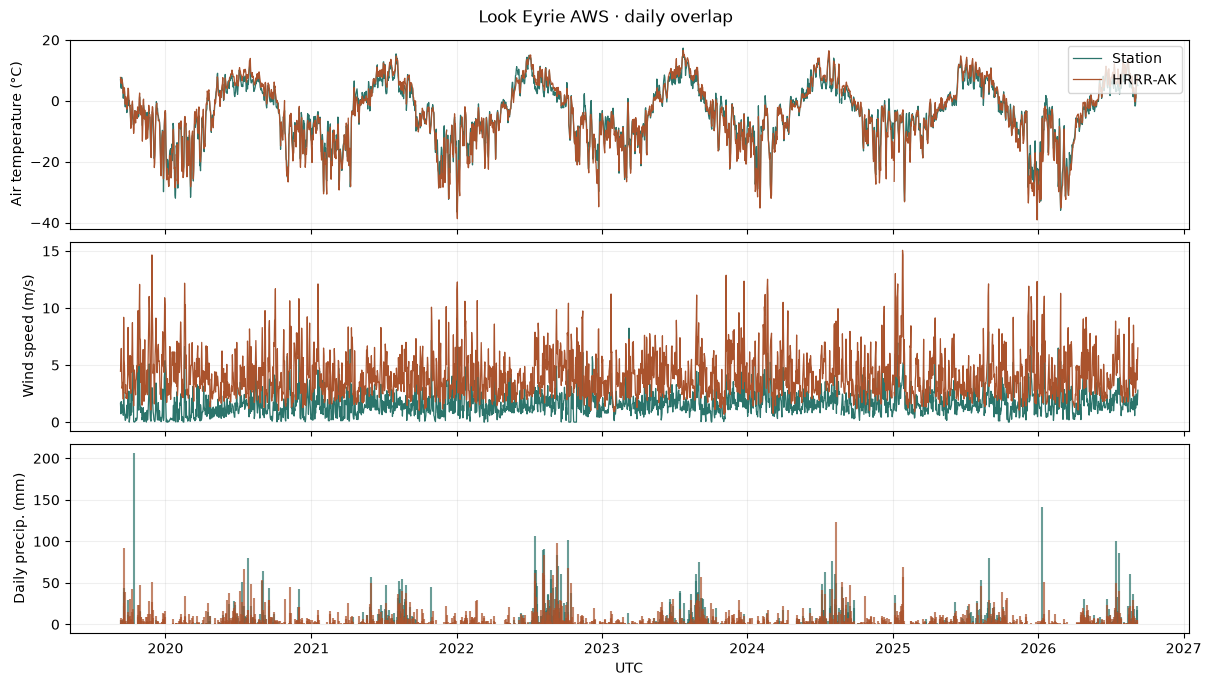

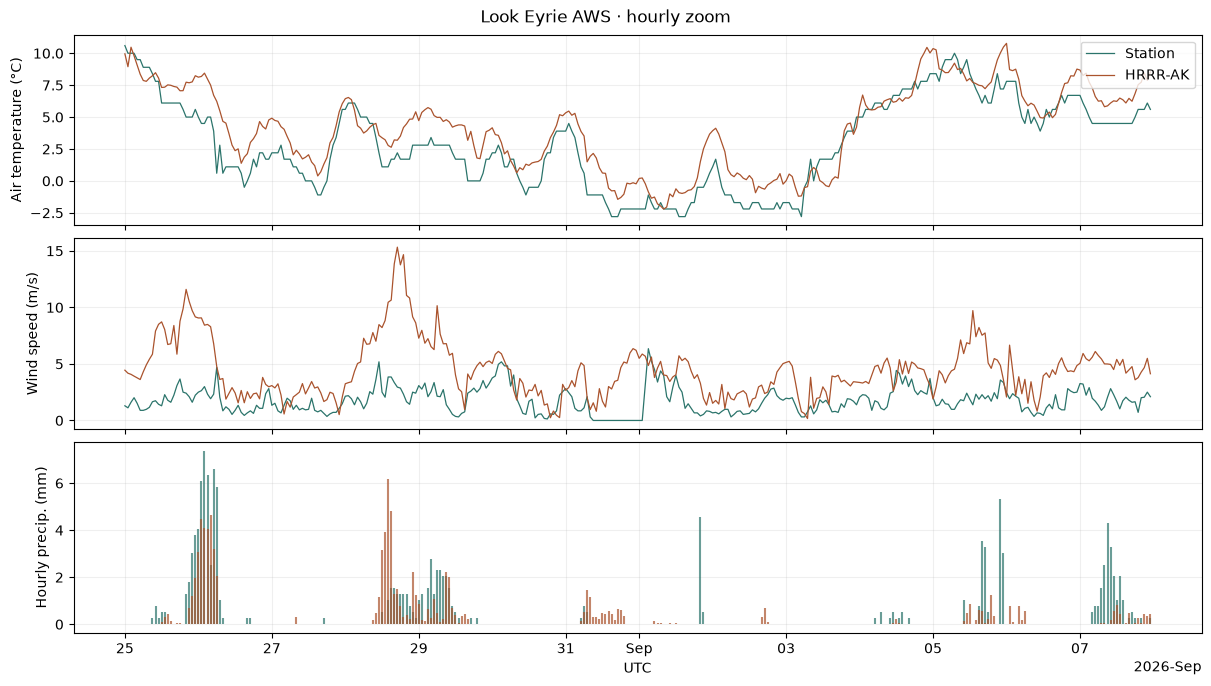

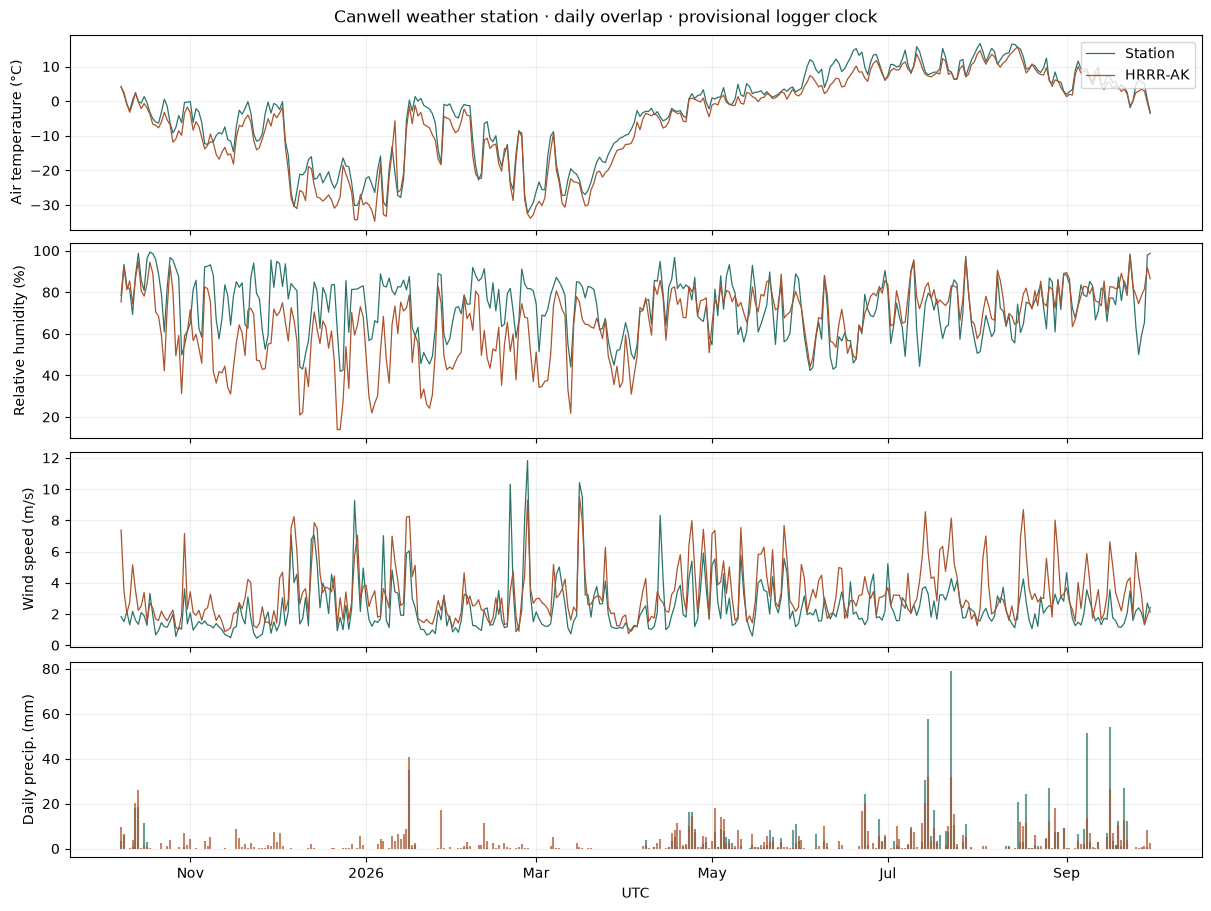

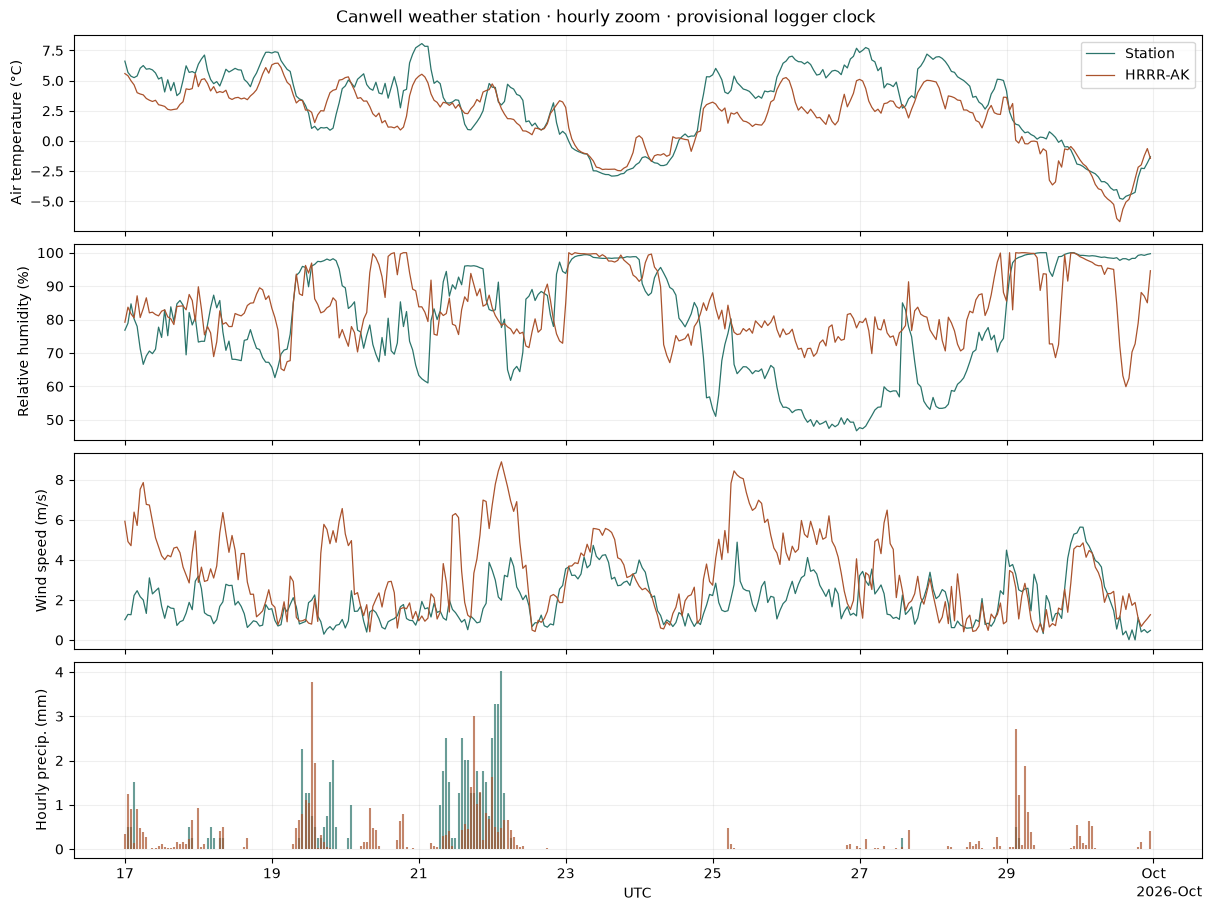

In [4]:
colors = {"Station": "#2b746b", "HRRR-AK": "#aa532d"}


def plot_weather(station, series, daily):
    variables = series["Station"].columns
    fig, axes = plt.subplots(len(variables), 1, figsize=(12, 2.25 * len(variables)),
                             sharex=True, layout="constrained")
    for ax, var in zip(axes, variables):
        values = series.xs(var, axis=1, level=1)
        precip = var == "precip_hourly"
        if daily:
            values = values.where(values.notna().all(axis=1), axis=0)
            days = values.resample("D", closed="right" if precip else "left")
            values = (days.sum(min_count=24) if precip
                      else days.mean().where(days.count().ge(18)))
        for source, color in colors.items():
            if precip:
                ax.vlines(values.index, 0, values[source], color=color, alpha=0.7, label=source)
            else:
                ax.plot(values.index, values[source], color=color, linewidth=0.9, label=source)
        interval = "Daily" if daily else "Hourly"
        ax.set_ylabel(f"{interval} precip. (mm)" if precip else labels[var])
        ax.grid(alpha=0.2)
    axes[0].legend(loc="upper right")
    axes[-1].set_xlabel("UTC")
    locator = mdates.AutoDateLocator()
    axes[-1].xaxis.set_major_locator(locator)
    axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    clock_note = " · provisional logger clock" if station == "Canwell weather station" else ""
    fig.suptitle(f"{station} · {'daily overlap' if daily else 'hourly zoom'}{clock_note}")
    plt.show()


for station, series in paired.items():
    plot_weather(station, series, daily=True)
    start = (pd.to_datetime(zoom_start[station], utc=True) if zoom_start[station]
             else series.index[-1].normalize() - pd.Timedelta(days=14))
    end = start + pd.Timedelta(days=14)
    window = series.loc[(series.index >= start) & (series.index < end)]
    if window.empty:
        print(f"{station}: the selected zoom window falls outside the model–station overlap.")
    else:
        plot_weather(station, window, daily=False)

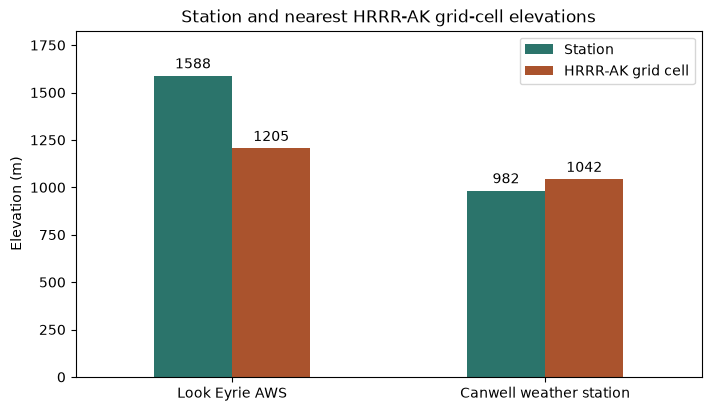

In [5]:
elevations = sites[["Station elevation (m)"]].join(grid_info[["Grid elevation (m)"]])
elevations.columns = ["Station", "HRRR-AK grid cell"]

fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
elevations.plot.bar(ax=ax, color=[colors["Station"], colors["HRRR-AK"]], rot=0)
ax.set(title="Station and nearest HRRR-AK grid-cell elevations",
       xlabel="", ylabel="Elevation (m)")
ax.margins(y=0.15)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.0f", padding=3)
plt.show()